# Multi-terminal 3D networks: subdivided boundary faces

Generalizes the two-terminal pipeline of `percolation_3d.ipynb` (source face x < 0.1, drain face x > 0.9) to **several terminals, each held at its own voltage**, motivated by vascular networks with several roots and leaves at different potentials.

The faces stay where they are, but instead of merging each face into one node, each is split by (y, z) quadrant into several terminals. Contact detection, percolation tracing, pruning and the local rebuild therefore reuse `run_full_pipeline_3d` unchanged; only the final grouping, merge and solve differ. `percolation_3d_spherical_terminals.ipynb` covers the general case of terminals anywhere in the cube.

The reduced solve of `ImpedanceCalculator.calculate()` (`M @ V_internal = -L_ib @ V_boundary`) already handles any number of boundary nodes; only the voltage vector `[1.0, 0.0]` and the single source-to-drain current were specific to two terminals. `multi_terminal_solver.solve_multi_terminal` removes that restriction and reports the net current at every terminal instead of one equivalent resistance.

---
## 1. Setup and imports

In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    utils_path = "/content/drive/MyDrive/ColabProject/utils"
    print("Environment: Google Colab")
except ImportError:
    utils_path = os.path.abspath(os.path.join(os.getcwd(), "..", "utils"))
    print("Environment: Local")

if utils_path not in sys.path:
    sys.path.append(utils_path)

print(f"Utils path: {utils_path}")


Environment: Local
Utils path: <project_root>/utils


In [2]:
from point_generator_3d import generate_points_3d
from pipeline_utils_3d import run_full_pipeline_3d_multi_terminal_faces
from multi_terminal_solver import (
    solve_multi_terminal, multi_terminal_pinv_currents,
    split_face_into_quadrants, print_terminal_roles,
)
from network_visualization_3d import plot_network_3d_colored_by_voltage, plot_network_3d_colored_by_resistance

print("Imports OK")


Imports OK


---
## Experiment tracking

In [3]:
from experiment_manager import setup_experiment

exp_manager = setup_experiment()


EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 810
  Timestamp: 20260727_135828
  Results directory: <project_root>/utils/../experiments/exp_810



---
## 2. Validation: hand-built networks with known answers

Two checks of `solve_multi_terminal`: against a closed-form nodal-analysis formula, and against `multi_terminal_pinv_currents`, an independent pseudoinverse solver that shares no code with it.

### 2.1 Three-terminal star (closed-form check)

One internal node connected to three terminals by edges of different lengths ($R_i = R_0 L_i$). Nodal analysis gives the internal voltage directly:

`Vc = (V1/R1 + V2/R2 + V3/R3) / (1/R1 + 1/R2 + 1/R3)`

In [4]:
intersections = [(0.5, 0.5, 0.5), (0, 0, 0), (2, 0, 0), (0, 3, 0)]
segment_to_nodes = {0: (0, 1), 1: (0, 2), 2: (0, 3)}
terminal_nodes = [1, 2, 3]
terminal_voltages = [1.0, 0.0, 0.6]
R0 = 1000.0

lengths = [np.linalg.norm(np.array(intersections[0]) - np.array(intersections[t])) for t in terminal_nodes]
expected_Vc = sum(v / L for v, L in zip(terminal_voltages, lengths)) / sum(1 / L for L in lengths)

res_star = solve_multi_terminal(intersections, segment_to_nodes, terminal_nodes, terminal_voltages,
                                k=R0, distance_dependent=True)

print(f"Internal node voltage: computed={res_star['voltages'][0]:.6f}  expected={expected_Vc:.6f}")
print(f"Current imbalance: {res_star['current_imbalance']:.2e} (should be ~0)")
assert abs(res_star['voltages'][0] - expected_Vc) < 1e-9
assert abs(res_star['current_imbalance']) < 1e-9
print("OK: matches the closed-form nodal-analysis formula exactly")


Internal node voltage: computed=0.646703  expected=0.646703
Current imbalance: -8.13e-20 (should be ~0)
OK: matches the closed-form nodal-analysis formula exactly


### 2.2 Four-terminal network with a loop (pseudoinverse cross-check)

Two internal nodes (A, B) and four terminals wired T1-A-B-T3-T4 plus a direct T1-B edge, so the network contains a cycle and no single nodal equation solves it. Cross-checked against `multi_terminal_pinv_currents`, which assembles the Laplacian directly from coordinates without `build_incidence_matrix`.

In [5]:
intersections_g = [(0.3, 0.5, 0.5), (0, 0, 0), (0, 1, 0), (1, 0, 1), (1, 1, 1), (0.7, 0.5, 0.5)]
# node indices: 0=A (internal), 1=T1, 2=T2, 3=T3, 4=T4, 5=B (internal)
segment_to_nodes_g = {0: (1, 0), 1: (2, 0), 2: (0, 5), 3: (5, 3), 4: (5, 4), 5: (1, 5)}
terminal_nodes_g = [1, 2, 3, 4]
terminal_voltages_g = [1.0, 0.3, 0.0, 0.7]

res_grid = solve_multi_terminal(intersections_g, segment_to_nodes_g, terminal_nodes_g, terminal_voltages_g,
                                k=R0, distance_dependent=True)
res_grid_pinv = multi_terminal_pinv_currents(intersections_g, segment_to_nodes_g, terminal_nodes_g, terminal_voltages_g,
                                             k=R0, distance_dependent=True)

print(f"Internal voltages (A, B): solver={res_grid['voltages'][0]:.6f}, {res_grid['voltages'][5]:.6f}")
print(f"                          pinv  ={res_grid_pinv['voltages'][0]:.6f}, {res_grid_pinv['voltages'][5]:.6f}")
print(f"Current imbalance: {res_grid['current_imbalance']:.2e} (should be ~0)")

assert np.allclose(res_grid['voltages'], res_grid_pinv['voltages'], atol=1e-9)
assert abs(res_grid['current_imbalance']) < 1e-9
for t in terminal_nodes_g:
    assert abs(res_grid['terminal_currents'][t] - res_grid_pinv['terminal_currents'][t]) < 1e-9
print("OK: matches the independent pseudoinverse solver exactly")


Internal voltages (A, B): solver=0.606939, 0.562091
                          pinv  =0.606939, 0.562091
Current imbalance: 8.13e-20 (should be ~0)
OK: matches the independent pseudoinverse solver exactly


---
## 3. Application to random 3D networks

Random networks as in `percolation_3d.ipynb` (isotropic sticks, contact-based connectivity), but the x < 0.1 and x > 0.9 faces are each split into (y, z) quadrants, and each quadrant becomes a terminal. By default every source-face quadrant gets the high voltage and every drain-face quadrant the low one, and each quadrant reports its own current, which shows how current splits across a face.

### 3.1 Up to four terminals (2 quadrants per face)

  Boundary conditions not met. No percolation possible.
Percolating multi-terminal network found on attempt 2
Terminals: 3 (out of up to 4 possible)   Voltages: [1.0, 0.0, 0.0]
Terminal currents: {256: np.float64(-0.0006381117306146951), 257: np.float64(0.00045256992372024547), 258: np.float64(0.0001855418068944571)}
Current imbalance: 7.51e-18 (should be ~0)
Terminal roles:
    node   256   V=+1.000   I=-6.381e-04   ->  SOURCE
    node   257   V=+0.000   I=+4.526e-04   <-  DRAIN
    node   258   V=+0.000   I=+1.855e-04   <-  DRAIN


<project_root>/utils/impedance_calculator.py:575: RuntimeWarning: divide by zero encountered in matmul
  L = A.T @ G_matrix @ A
<project_root>/utils/impedance_calculator.py:575: RuntimeWarning: overflow encountered in matmul
  L = A.T @ G_matrix @ A
<project_root>/utils/impedance_calculator.py:575: RuntimeWarning: invalid value encountered in matmul
  L = A.T @ G_matrix @ A
<project_root>/utils/impedance_calculator.py:679: RuntimeWarning: divide by zero encountered in matmul
  voltage_drops = -A @ V_full  # Voltage drop across each edge
<project_root>/utils/impedance_calculator.py:679: RuntimeWarning: overflow encountered in matmul
  voltage_drops = -A @ V_full  # Voltage drop across each edge
<project_root>/utils/impedance_calculator.py:679: RuntimeWarning: invalid value encountered in matmul
  voltage_drops = -A @ V_full  # Voltage drop across each edge
<project_root>/utils/impedance_calculator.py:680: RuntimeWarning: divide by zero encountered in matmul
  I = G_matrix @ voltage_drop

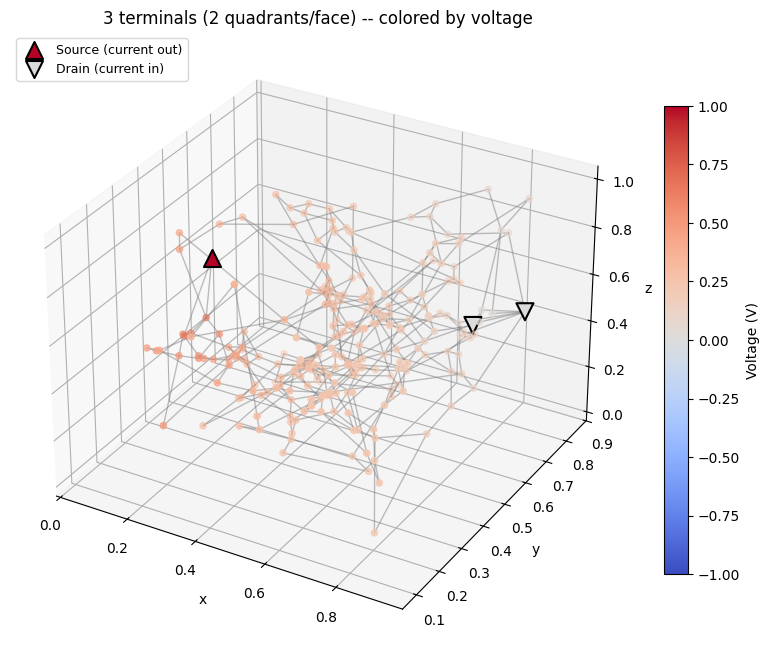

  [OK] Figure saved: faces_4terminals_voltage.png


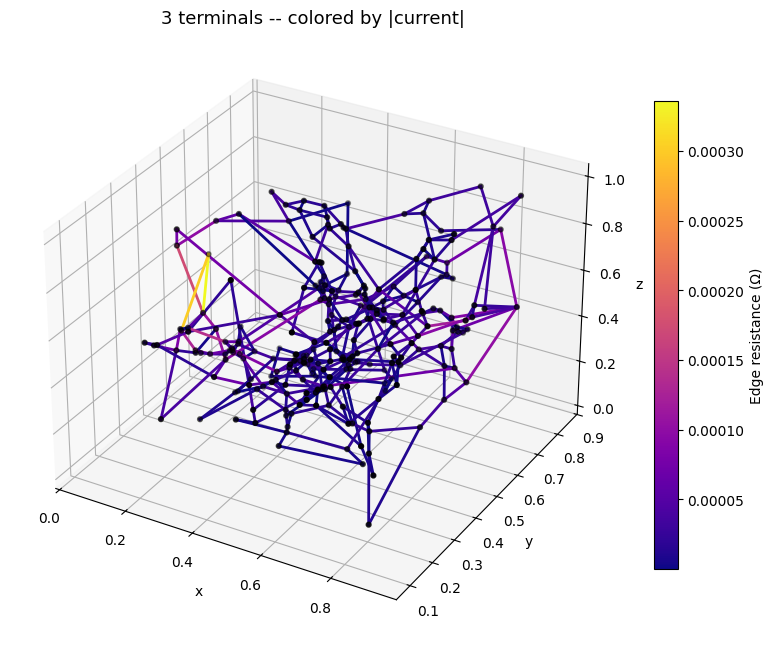

  [OK] Figure saved: faces_4terminals_current.png


'<project_root>/utils/../experiments/exp_810/faces_4terminals_current.png'

In [6]:
N4, a4, cd4 = 80, 0.6, 0.08

np.random.seed(10)
points_1, points_2, dirs = [], [], []
generate_points_3d(N4, points_1, points_2, dirs, a4, enforce_bounds=True)

res4 = None
for attempt in range(1, 51):
    res4 = run_full_pipeline_3d_multi_terminal_faces(
        points_1, points_2, N=N4, a=a4, contact_distance=cd4,
        n_subdivisions_per_face=2, k=1000.0, verbose=False,
    )
    if res4.get("has_percolation"):
        break
    points_1, points_2, dirs = [], [], []
    generate_points_3d(N4, points_1, points_2, dirs, a4, enforce_bounds=True)

n_terminals_4 = len(res4['terminal_node_indices'])
print(f"Percolating multi-terminal network found on attempt {attempt}")
print(f"Terminals: {n_terminals_4} (out of up to 4 possible)   Voltages: {res4['terminal_voltages']}")
print(f"Terminal currents: {res4['solve']['terminal_currents']}")
print(f"Current imbalance: {res4['solve']['current_imbalance']:.2e} (should be ~0)")
assert abs(res4['solve']['current_imbalance']) < 1e-6 * max(abs(v) for v in res4['solve']['terminal_currents'].values())

print_terminal_roles(res4['terminal_node_indices'], res4['terminal_voltages'], res4['solve']['terminal_currents'],
                    title="Terminal roles:")

fig = plot_network_3d_colored_by_voltage(
    res4["merged_intersections"], res4["merged_segment_to_nodes"], res4["solve"]["voltages"],
    terminal_nodes=res4["terminal_node_indices"], terminal_currents=res4["solve"]["terminal_currents"], title=f"{n_terminals_4} terminals (2 quadrants/face) -- colored by voltage"
)
plt.show()
exp_manager.save_figure(fig, "faces_4terminals_voltage.png")

fig2 = plot_network_3d_colored_by_resistance(
    res4["merged_intersections"], res4["merged_segment_to_nodes"], np.abs(res4["solve"]["currents"]),
    title=f"{n_terminals_4} terminals -- colored by |current|", cmap_name="plasma"
)
plt.show()
exp_manager.save_figure(fig2, "faces_4terminals_current.png")


### 3.2 Up to eight terminals (4 quadrants per face)

Percolating multi-terminal network found on attempt 1
Terminals: 5 (out of up to 8 possible)   Voltages: [1.0, 0.0, 0.0, 0.0, 0.0]
Terminal currents: {487: np.float64(-0.0006459610354895007), 488: np.float64(0.00019528143492106255), 489: np.float64(7.175223518360507e-05), 490: np.float64(0.00015476033000743594), 491: np.float64(0.0002241670353773872)}
Current imbalance: -9.92e-18 (should be ~0)
Terminal roles:
    node   487   V=+1.000   I=-6.460e-04   ->  SOURCE
    node   488   V=+0.000   I=+1.953e-04   <-  DRAIN
    node   489   V=+0.000   I=+7.175e-05   <-  DRAIN
    node   490   V=+0.000   I=+1.548e-04   <-  DRAIN
    node   491   V=+0.000   I=+2.242e-04   <-  DRAIN


<project_root>/utils/multi_terminal_solver.py:108: RuntimeWarning: divide by zero encountered in matmul
  b = -L_ib @ V_boundary
<project_root>/utils/multi_terminal_solver.py:108: RuntimeWarning: overflow encountered in matmul
  b = -L_ib @ V_boundary
<project_root>/utils/multi_terminal_solver.py:108: RuntimeWarning: invalid value encountered in matmul
  b = -L_ib @ V_boundary


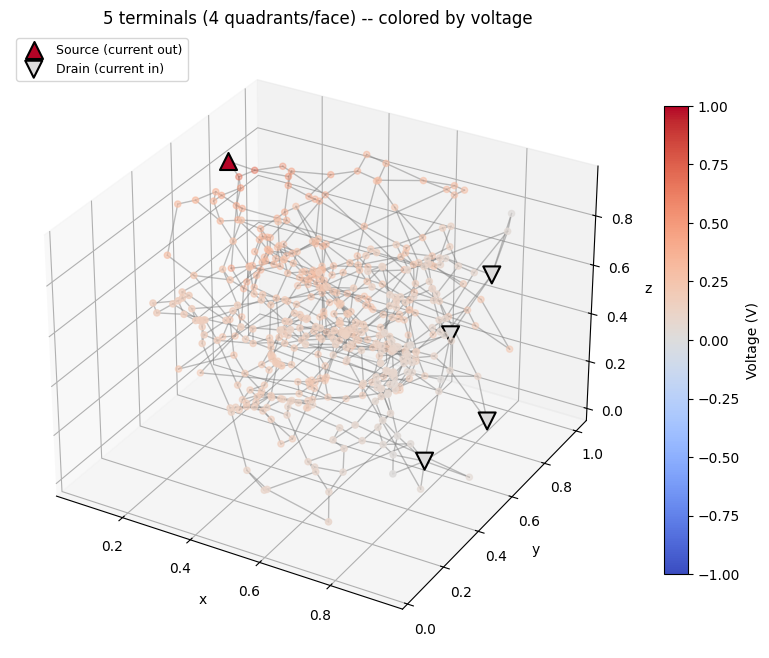

  [OK] Figure saved: faces_8terminals_voltage.png


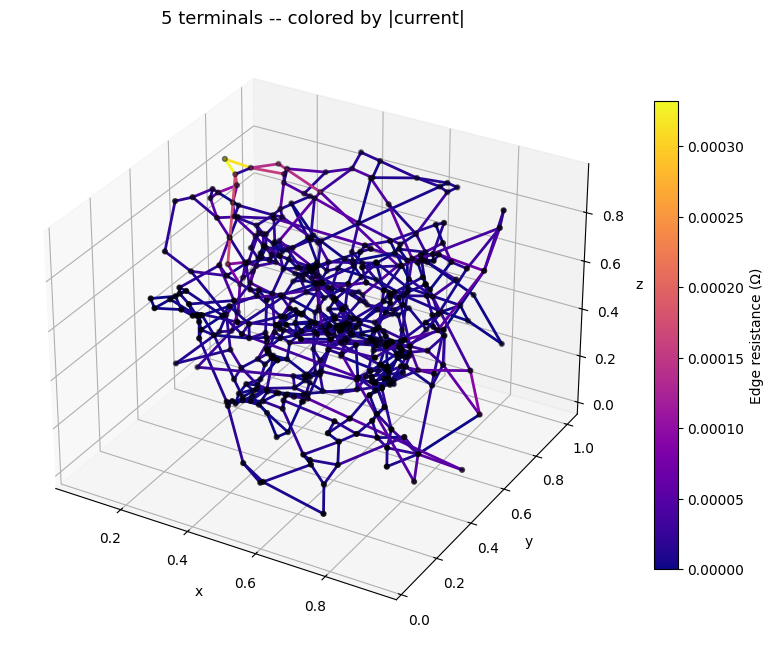

  [OK] Figure saved: faces_8terminals_current.png


'<project_root>/utils/../experiments/exp_810/faces_8terminals_current.png'

In [7]:
N8, a8, cd8 = 100, 0.6, 0.08

np.random.seed(20)
points_1, points_2, dirs = [], [], []
generate_points_3d(N8, points_1, points_2, dirs, a8, enforce_bounds=True)

res8 = None
for attempt in range(1, 51):
    res8 = run_full_pipeline_3d_multi_terminal_faces(
        points_1, points_2, N=N8, a=a8, contact_distance=cd8,
        n_subdivisions_per_face=4, k=1000.0, verbose=False,
    )
    if res8.get("has_percolation"):
        break
    points_1, points_2, dirs = [], [], []
    generate_points_3d(N8, points_1, points_2, dirs, a8, enforce_bounds=True)

n_terminals_8 = len(res8['terminal_node_indices'])
print(f"Percolating multi-terminal network found on attempt {attempt}")
print(f"Terminals: {n_terminals_8} (out of up to 8 possible)   Voltages: {res8['terminal_voltages']}")
print(f"Terminal currents: {res8['solve']['terminal_currents']}")
print(f"Current imbalance: {res8['solve']['current_imbalance']:.2e} (should be ~0)")
assert abs(res8['solve']['current_imbalance']) < 1e-6 * max(abs(v) for v in res8['solve']['terminal_currents'].values())

print_terminal_roles(res8['terminal_node_indices'], res8['terminal_voltages'], res8['solve']['terminal_currents'],
                    title="Terminal roles:")

fig = plot_network_3d_colored_by_voltage(
    res8["merged_intersections"], res8["merged_segment_to_nodes"], res8["solve"]["voltages"],
    terminal_nodes=res8["terminal_node_indices"], terminal_currents=res8["solve"]["terminal_currents"], title=f"{n_terminals_8} terminals (4 quadrants/face) -- colored by voltage"
)
plt.show()
exp_manager.save_figure(fig, "faces_8terminals_voltage.png")

fig2 = plot_network_3d_colored_by_resistance(
    res8["merged_intersections"], res8["merged_segment_to_nodes"], np.abs(res8["solve"]["currents"]),
    title=f"{n_terminals_8} terminals -- colored by |current|", cmap_name="plasma"
)
plt.show()
exp_manager.save_figure(fig2, "faces_8terminals_current.png")


### 3.3 Denser, shorter-stick network (2 quadrants/face)

Shorter sticks at higher density with a tighter `contact_distance`: many small contacts instead of fewer large ones. Still 2 quadrants per face, as in 3.1, so differences come from the network and not from the terminal count.

Percolating multi-terminal network found on attempt 1
Terminals: 4 (out of up to 4 possible)   Voltages: [1.0, 1.0, 0.0, 0.0]
Terminal currents: {331: np.float64(0.0), 332: np.float64(-0.00033772945417339783), 333: np.float64(0.00020267375429003186), 334: np.float64(0.00013505569988337126)}
Current imbalance: 5.29e-18 (should be ~0)
Terminal roles:
    node   331   V=+1.000   I=+0.000e+00   ->  SOURCE
    node   332   V=+1.000   I=-3.377e-04   ->  SOURCE
    node   333   V=+0.000   I=+2.027e-04   <-  DRAIN
    node   334   V=+0.000   I=+1.351e-04   <-  DRAIN


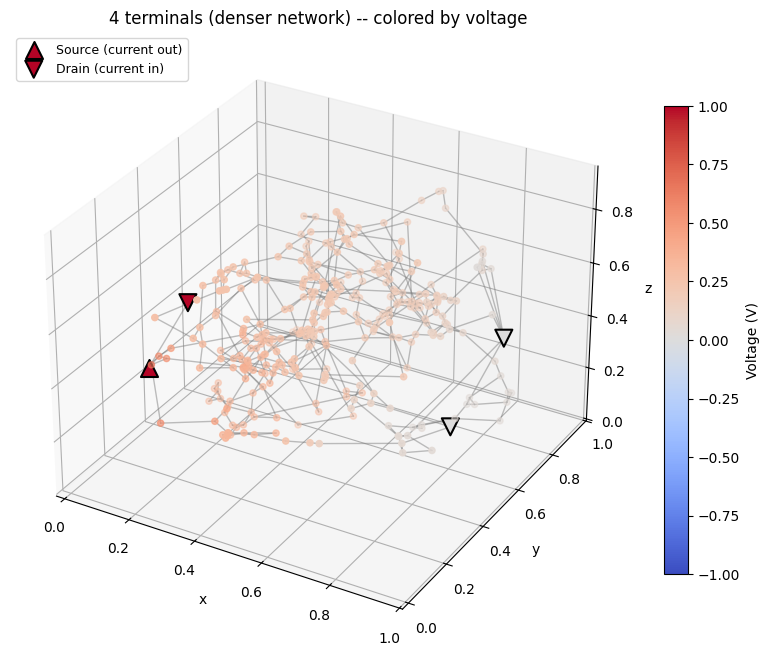

  [OK] Figure saved: faces_denser_voltage.png


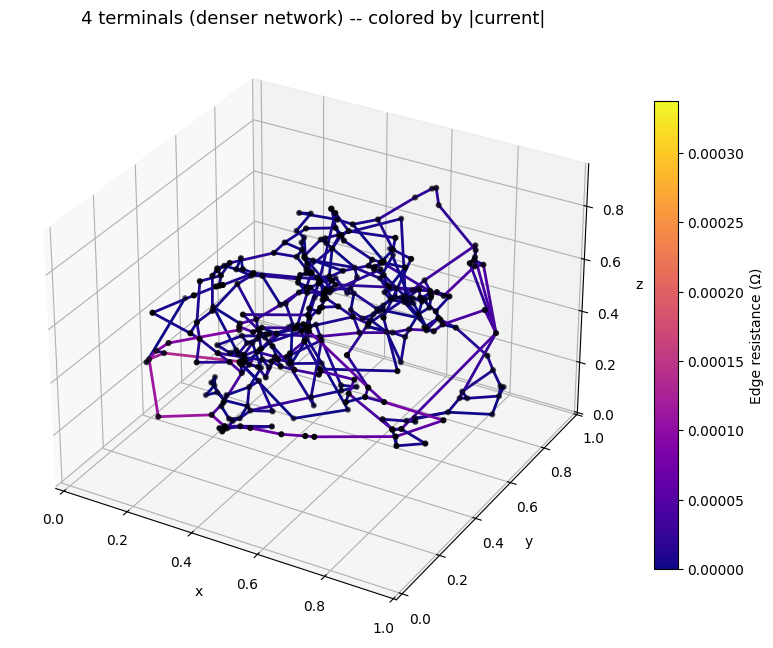

  [OK] Figure saved: faces_denser_current.png


'<project_root>/utils/../experiments/exp_810/faces_denser_current.png'

In [8]:
N_dense, a_dense, cd_dense = 180, 0.35, 0.05

np.random.seed(50)
points_1, points_2, dirs = [], [], []
generate_points_3d(N_dense, points_1, points_2, dirs, a_dense, enforce_bounds=True)

res_dense = None
for attempt in range(1, 51):
    res_dense = run_full_pipeline_3d_multi_terminal_faces(
        points_1, points_2, N=N_dense, a=a_dense, contact_distance=cd_dense,
        n_subdivisions_per_face=2, k=1000.0, verbose=False,
    )
    if res_dense.get("has_percolation"):
        break
    points_1, points_2, dirs = [], [], []
    generate_points_3d(N_dense, points_1, points_2, dirs, a_dense, enforce_bounds=True)

n_terminals_dense = len(res_dense['terminal_node_indices'])
print(f"Percolating multi-terminal network found on attempt {attempt}")
print(f"Terminals: {n_terminals_dense} (out of up to 4 possible)   Voltages: {res_dense['terminal_voltages']}")
print(f"Terminal currents: {res_dense['solve']['terminal_currents']}")
print(f"Current imbalance: {res_dense['solve']['current_imbalance']:.2e} (should be ~0)")
assert abs(res_dense['solve']['current_imbalance']) < 1e-6 * max(abs(v) for v in res_dense['solve']['terminal_currents'].values())

print_terminal_roles(res_dense['terminal_node_indices'], res_dense['terminal_voltages'], res_dense['solve']['terminal_currents'],
                    title="Terminal roles:")

fig = plot_network_3d_colored_by_voltage(
    res_dense["merged_intersections"], res_dense["merged_segment_to_nodes"], res_dense["solve"]["voltages"],
    terminal_nodes=res_dense["terminal_node_indices"], terminal_currents=res_dense["solve"]["terminal_currents"], title=f"{n_terminals_dense} terminals (denser network) -- colored by voltage"
)
plt.show()
exp_manager.save_figure(fig, "faces_denser_voltage.png")

fig2 = plot_network_3d_colored_by_resistance(
    res_dense["merged_intersections"], res_dense["merged_segment_to_nodes"], np.abs(res_dense["solve"]["currents"]),
    title=f"{n_terminals_dense} terminals (denser network) -- colored by |current|", cmap_name="plasma"
)
plt.show()
exp_manager.save_figure(fig2, "faces_denser_current.png")


---
## Notes

- `run_full_pipeline_3d` is reused unchanged, including the `pre_merge_*` fields it exposes for this purpose; only the tail (quadrant grouping, `merge_terminal_groups`, `solve_multi_terminal`) is new.
- `current_imbalance ≈ 0` (Kirchhoff's current law over the whole network) is checked in every cell. It cannot detect a terminal with the wrong role, since any assignment conserves current globally.
- The default voltages are face-consistent: 1.0 on every non-empty source quadrant and 0.0 on every non-empty drain quadrant. An earlier version alternated `[1, 0, 1, 0, ...]` by list position, which could put a source voltage on a drain-face quadrant and drive a spurious current between two quadrants of the same face.
- Empty quadrants are dropped (`drop_empty_terminals=True`), so the printed terminal count can be below `2 × n_subdivisions_per_face`.
- The stored outputs (`exp_810`, 2026-07-27) of 3.1 and 3.2 contain divide-by-zero and overflow `RuntimeWarning`s from the solvers; the printed current imbalances are still near zero.
- `percolation_3d_spherical_terminals.ipynb` drops the face convention and needs the generic connectivity and pruning path (`connected_components`, `prune_dead_end_nodes_generic`).

---
## 4. Save consolidated summary

In [9]:
summary = {
    "experiment": exp_manager.get_info(),
    "validation": {
        "star_Vc": res_star["voltages"][0],
        "star_Vc_expected": expected_Vc,
        "grid_current_imbalance": res_grid["current_imbalance"],
    },
    "four_terminal_network": {
        "N": N4, "a": a4, "contact_distance": cd4,
        "terminal_voltages": res4["terminal_voltages"],
        "terminal_currents": {str(k): v for k, v in res4["solve"]["terminal_currents"].items()},
        "current_imbalance": res4["solve"]["current_imbalance"],
    },
    "eight_terminal_network": {
        "N": N8, "a": a8, "contact_distance": cd8,
        "terminal_voltages": res8["terminal_voltages"],
        "terminal_currents": {str(k): v for k, v in res8["solve"]["terminal_currents"].items()},
        "current_imbalance": res8["solve"]["current_imbalance"],
    },
    "denser_network": {
        "N": N_dense, "a": a_dense, "contact_distance": cd_dense,
        "terminal_voltages": res_dense["terminal_voltages"],
        "terminal_currents": {str(k): v for k, v in res_dense["solve"]["terminal_currents"].items()},
        "current_imbalance": res_dense["solve"]["current_imbalance"],
    },
}

exp_manager.save_json(summary, "multi_terminal_faces_summary.json")

print(f"\nAll results saved to: {exp_manager.experiment_dir}")
for f in sorted(os.listdir(exp_manager.experiment_dir)):
    print(f"  - {f}")


  [OK] JSON saved: multi_terminal_faces_summary.json

All results saved to: <project_root>/utils/../experiments/exp_810
  - faces_4terminals_current.png
  - faces_4terminals_voltage.png
  - faces_8terminals_current.png
  - faces_8terminals_voltage.png
  - faces_denser_current.png
  - faces_denser_voltage.png
  - multi_terminal_faces_summary.json
